# Лабораторная работа №3. Кластеризация
### Отчет по практическому заданию курса «Машинное обучение»

### 1) Введение. Краткое описание целей и задач работы

- **Цель работы:** изучить алгоритмы кластеризации, оценить качество разбиения и интерпретировать полученные группы.
- **Постановка задачи:**
  1. Загрузить датасет и описать признаки, пропуски и распределения.
  2. Проверить, есть ли смысл кластеризовать данные, и отделить известные метки от признаков.
  3. Стандартизовать числовые признаки и по матрице рассеивания выбрать методы.
  4. Подобрать число кластеров методом локтя и силуэтом.
  5. Построить K-means и EM-кластеризацию (Gaussian Mixture), посчитать внутренние и внешние метрики.
  6. Проверить, как тип ковариации GMM меняет качество.
  7. Обучить глубокую кластеризацию DEC: автокодировщик и дообучение мягких назначений. Сравнить её с классическими методами.
- **Датасет:** Dry Bean Dataset с Kaggle. Одно наблюдение — одно зерно фасоли, снятое системой компьютерного зрения.


In [ ]:
from pathlib import Path
import os
import urllib.request

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from IPython.display import display
from scipy.stats import shapiro
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    normalized_mutual_info_score,
    rand_score,
    silhouette_score,
)
from sklearn.metrics.cluster import pair_confusion_matrix
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
OUTPUT_DIR = ROOT / "output"
DATA_PATH = DATA_DIR / "dry-bean.csv"
DATA_URL = "https://www.stat.rice.edu/~scottdw/stat541/PROJECTS/uci-data/DRY-BEAN/Dry_Bean_Dataset.csv"

RANDOM_STATE = 42
TARGET = "Class"
CORR_THRESHOLD = 0.95

FEATURES = [
    "Area",
    "Perimeter",
    "MajorAxisLength",
    "MinorAxisLength",
    "AspectRation",
    "Eccentricity",
    "ConvexArea",
    "EquivDiameter",
    "Extent",
    "Solidity",
    "roundness",
    "Compactness",
    "ShapeFactor1",
    "ShapeFactor2",
    "ShapeFactor3",
    "ShapeFactor4",
]
LABELS = {
    "Area": "Площадь",
    "Perimeter": "Периметр",
    "MajorAxisLength": "Большая ось",
    "MinorAxisLength": "Малая ось",
    "AspectRation": "Соотношение осей",
    "Eccentricity": "Эксцентриситет",
    "ConvexArea": "Выпуклая площадь",
    "EquivDiameter": "Эквивалентный диаметр",
    "Extent": "Заполненность",
    "Solidity": "Плотность",
    "roundness": "Округлость",
    "Compactness": "Компактность",
    "ShapeFactor1": "Форм-фактор 1",
    "ShapeFactor2": "Форм-фактор 2",
    "ShapeFactor3": "Форм-фактор 3",
    "ShapeFactor4": "Форм-фактор 4",
    "Class": "Сорт",
}
VARIETY = {
    "SEKER": "Секер",
    "BARBUNYA": "Барбунья",
    "BOMBAY": "Бомбей",
    "CALI": "Кали",
    "HOROZ": "Хороз",
    "SIRA": "Сира",
    "DERMASON": "Дермасон",
}

np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", font="DejaVu Sans")
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 140

DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


In [ ]:
if not DATA_PATH.exists() or DATA_PATH.stat().st_size == 0:
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

raw = pd.read_csv(DATA_PATH)
display(raw.head())
schema = pd.DataFrame({
    "тип": raw.dtypes.astype(str),
    "пропуски": raw.isna().sum(),
    "уникальные": raw.nunique(),
})
schema.index = [LABELS.get(name, name) for name in schema.index]
display(schema)
class_counts = raw[TARGET].value_counts().rename(index=VARIETY)
display(class_counts.to_frame("число зёрен"))
print(f"Наблюдений: {len(raw)}")
print(f"Признаков: {raw.shape[1] - 1}")
print(f"Пропусков всего: {int(raw.isna().sum().sum())}")


Наблюдений: 13611
Признаков: 16
Пропусков всего: 0


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


,тип,пропуски,уникальные
Площадь,int64,0,12011
Периметр,float64,0,13351
Большая ось,float64,0,13543
Малая ось,float64,0,13543
Соотношение осей,float64,0,13543
Эксцентриситет,float64,0,13543
Выпуклая площадь,int64,0,12066
Эквивалентный диаметр,float64,0,12011
Заполненность,float64,0,13535
Плотность,float64,0,13522


,число зёрен
Class,
Дермасон,3546
Сира,2636
Секер,2027
Хороз,1928
Кали,1630
Барбунья,1322
Бомбей,522


### Пояснение к датасету

- **Источник:** Dry Bean Dataset, публикация на Kaggle: https://www.kaggle.com/datasets/muratkokludataset/dry-bean-dataset. Файл сохранён в `data/dry-bean.csv`.
- **Объём:** **13611** зёрен и **16** числовых признаков. Пропусков нет (0).
- **Признаки:** площадь, периметр, оси, соотношение осей, эксцентриситет, выпуклая площадь, эквивалентный диаметр, заполненность рамки, плотность, округлость, компактность и четыре форм-фактора. В исходном файле соотношение осей называется `AspectRation`.
- **Сорта:** 7 известных сортов. Они не входят в матрицу признаков и нужны только как внешняя проверка. Чаще всего встречаются Дермасон и Сира, реже всего Бомбей.
- **Нормальность.** Тест Шапиро–Уилка на случайных 500 значениях отвергает нормальность у **16** признаков из 16. Сильнее всего асимметрия у: Площадь (2,95), Выпуклая площадь (2,94), Форм-фактор 4 (-2,76). Гистограммы площади и связанных с ней размеров имеют длинный правый хвост.


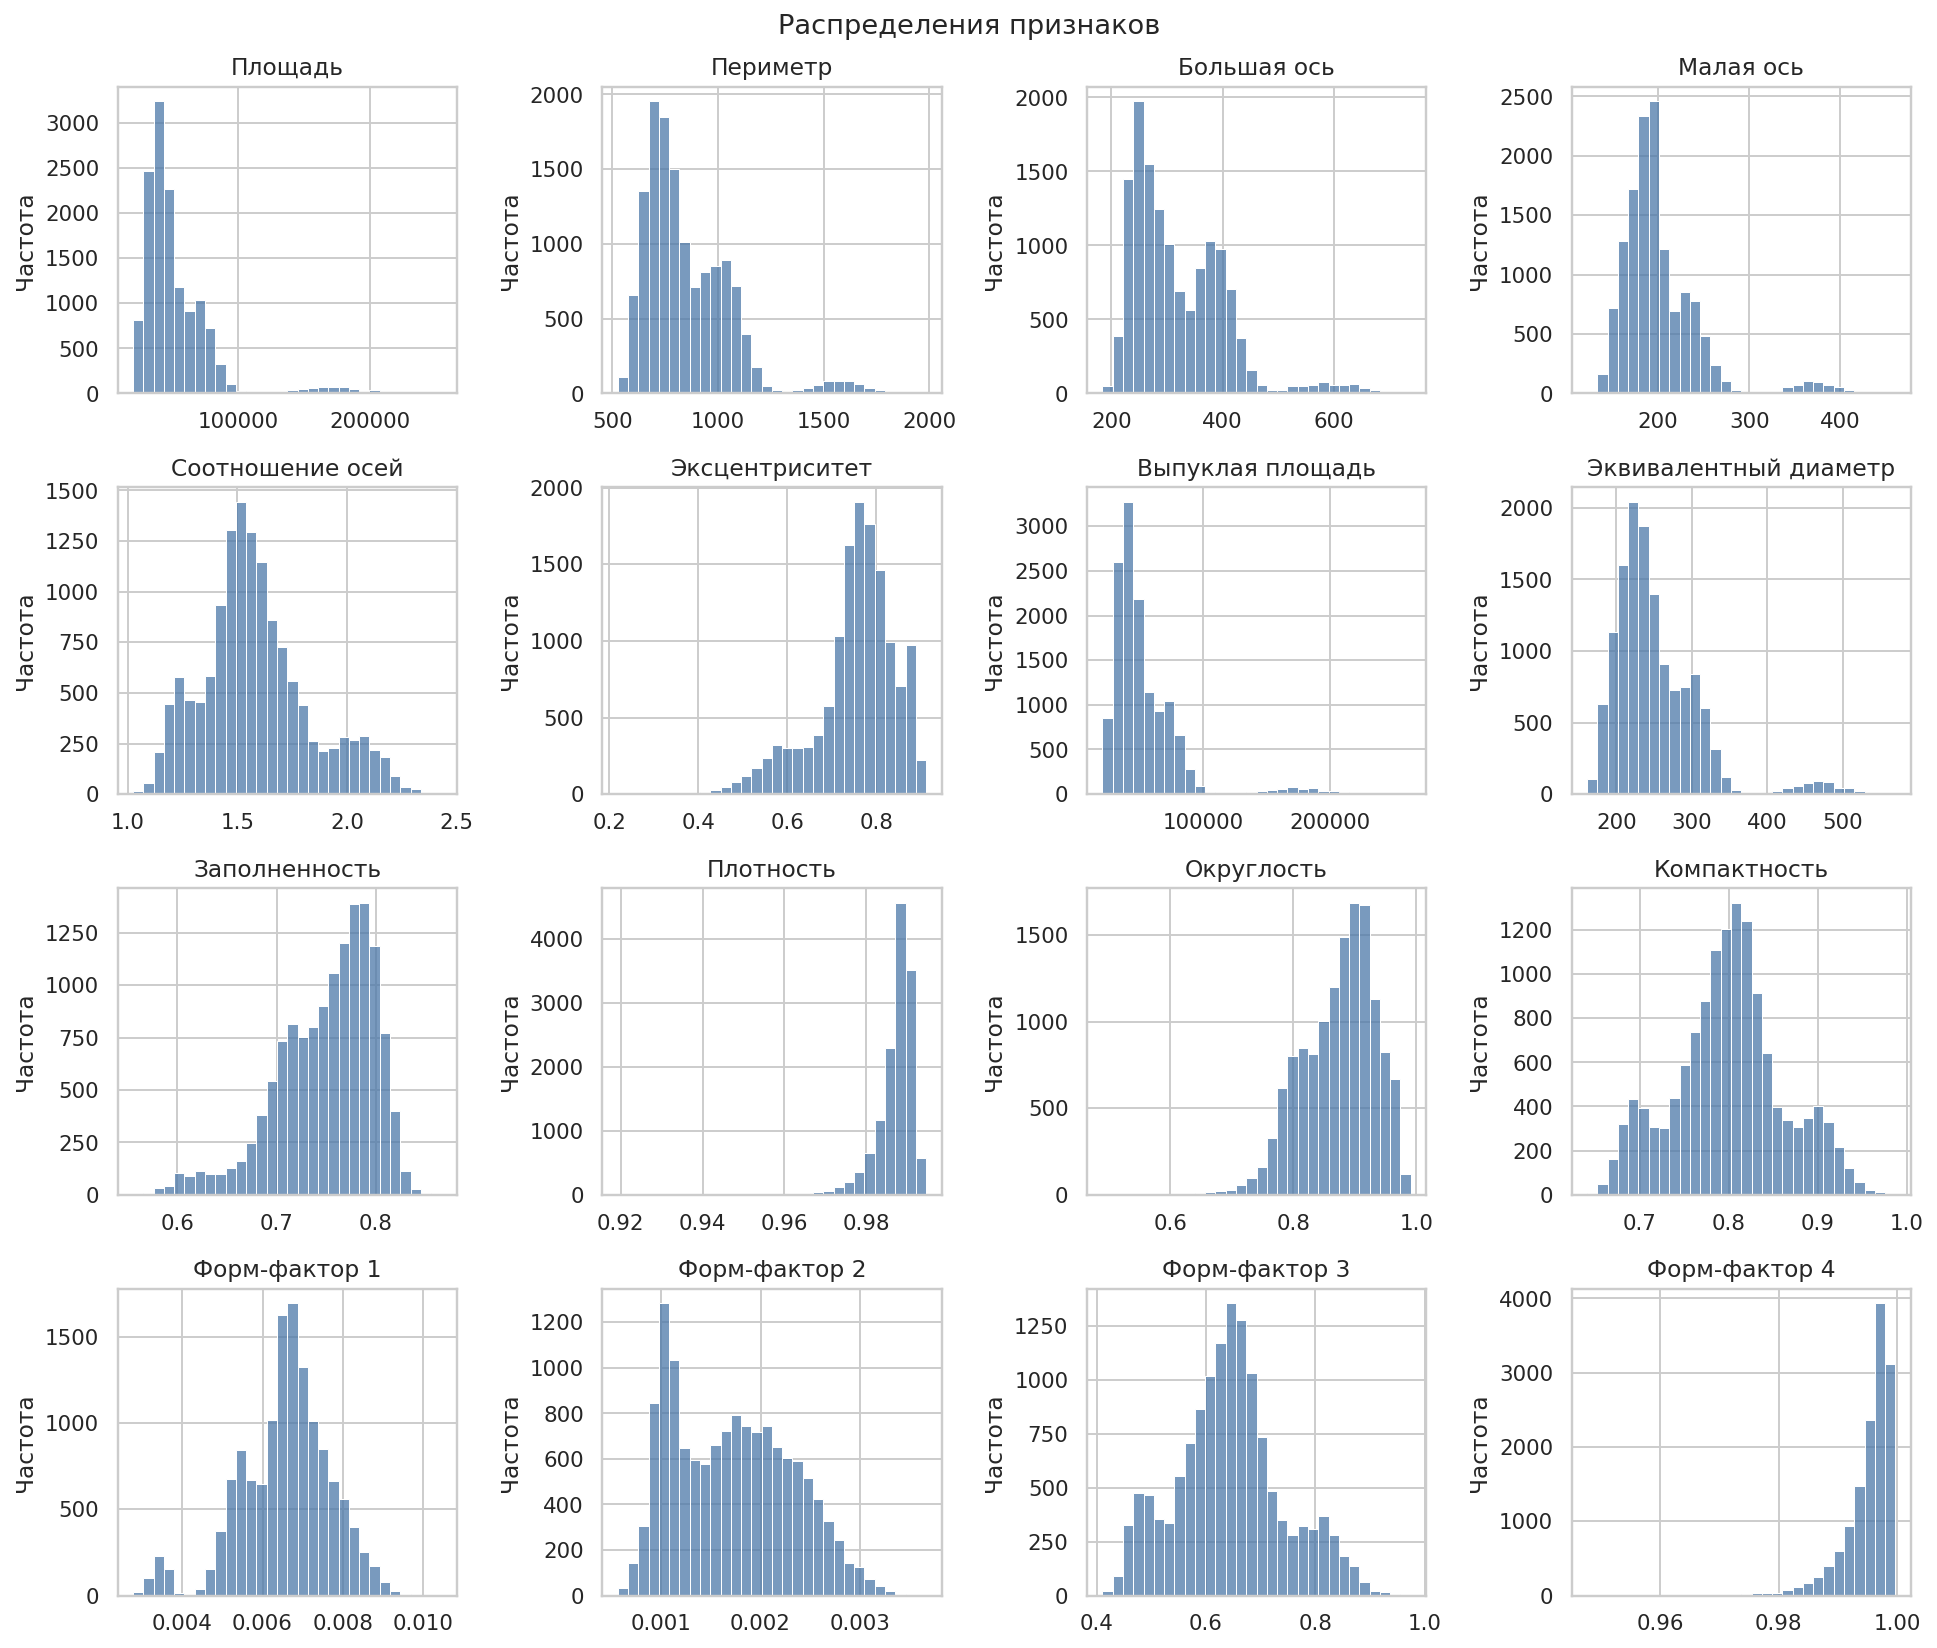

,асимметрия,p-value Шапиро
Признак,,
Площадь,2.953,0.0
Периметр,1.626,0.0
Большая ось,1.358,0.0
Малая ось,2.238,0.0
Соотношение осей,0.583,0.0
Эксцентриситет,-1.063,0.0
Выпуклая площадь,2.942,0.0
Эквивалентный диаметр,1.949,0.0
Заполненность,-0.895,0.0


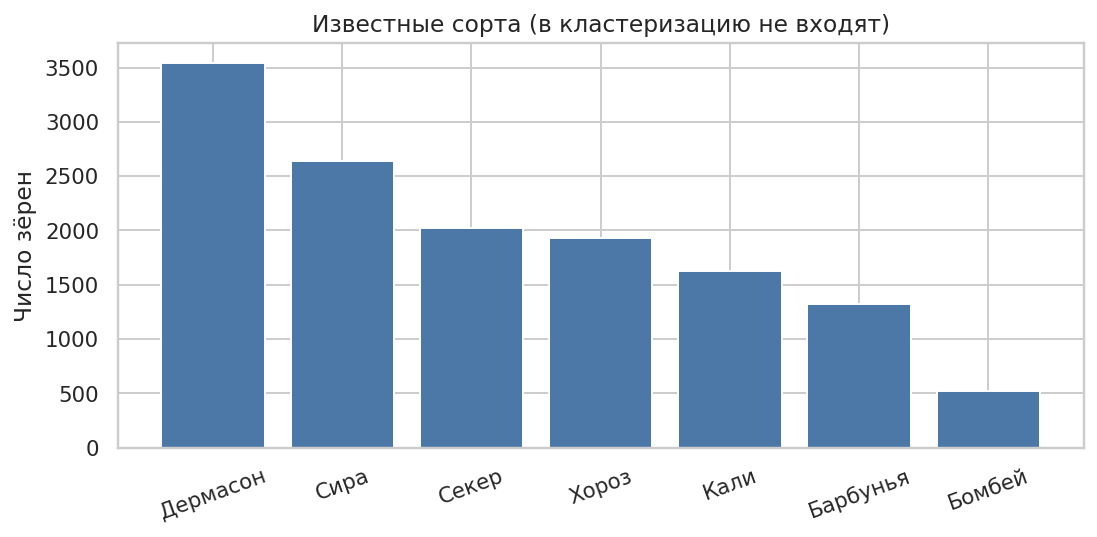

In [ ]:
fig, axes = plt.subplots(4, 4, figsize=(14, 12))
for ax, column in zip(axes.ravel(), FEATURES):
    sns.histplot(raw[column], bins=30, ax=ax, color="#4C78A8")
    ax.set_title(LABELS[column])
    ax.set_xlabel("")
    ax.set_ylabel("Частота")
fig.suptitle("Распределения признаков", fontsize=14)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_histograms.png", bbox_inches="tight")
plt.show()

normality_rows = []
rng = np.random.default_rng(RANDOM_STATE)
for column in FEATURES:
    sample = raw[column].to_numpy()
    if len(sample) > 500:
        sample = rng.choice(sample, size=500, replace=False)
    stat, pvalue = shapiro(sample)
    normality_rows.append({
        "Признак": LABELS[column],
        "асимметрия": float(raw[column].skew()),
        "p-value Шапиро": float(pvalue),
    })
normality = pd.DataFrame(normality_rows).set_index("Признак")
normality.to_csv(OUTPUT_DIR / "normality.csv", encoding="utf-8-sig")
display(normality.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(class_counts.index, class_counts.values, color="#4C78A8")
ax.set_ylabel("Число зёрен")
ax.set_title("Известные сорта (в кластеризацию не входят)")
ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02_varieties.png", bbox_inches="tight")
plt.show()


### Пояснение к выбросам и условиям кластеризации

- По правилу 1,5 межквартильных размаха хотя бы один необычный признак есть у **3017** строк. Среди отмеченных строк доля Бомбея равна 0,17: крайние значения есть и у Хороза, Секера и Кали.
- Это не сбои измерения, а зёрна с необычным размером или формой. Строки остаются в выборке: иначе вместе с хвостом исчезнут целые сорта, в том числе весь Бомбей.
- **Условия кластеризации.** В признаки сорт не подаётся, так что алгоритм не видит готовых классов. Группы при этом ожидаемы: сорта отличаются размером и вытянутостью. Крайние точки по IQR принадлежат нескольким реальным сортам, поэтому выборку не чистим.


Строк хотя бы с одним выбросом: 3017
Доля сорта Бомбей среди таких строк: 0.173


,выбросы по IQR
Признак,
Площадь,551
Периметр,500
Большая ось,379
Малая ось,569
Соотношение осей,473
Эксцентриситет,843
Выпуклая площадь,550
Эквивалентный диаметр,526
Заполненность,275


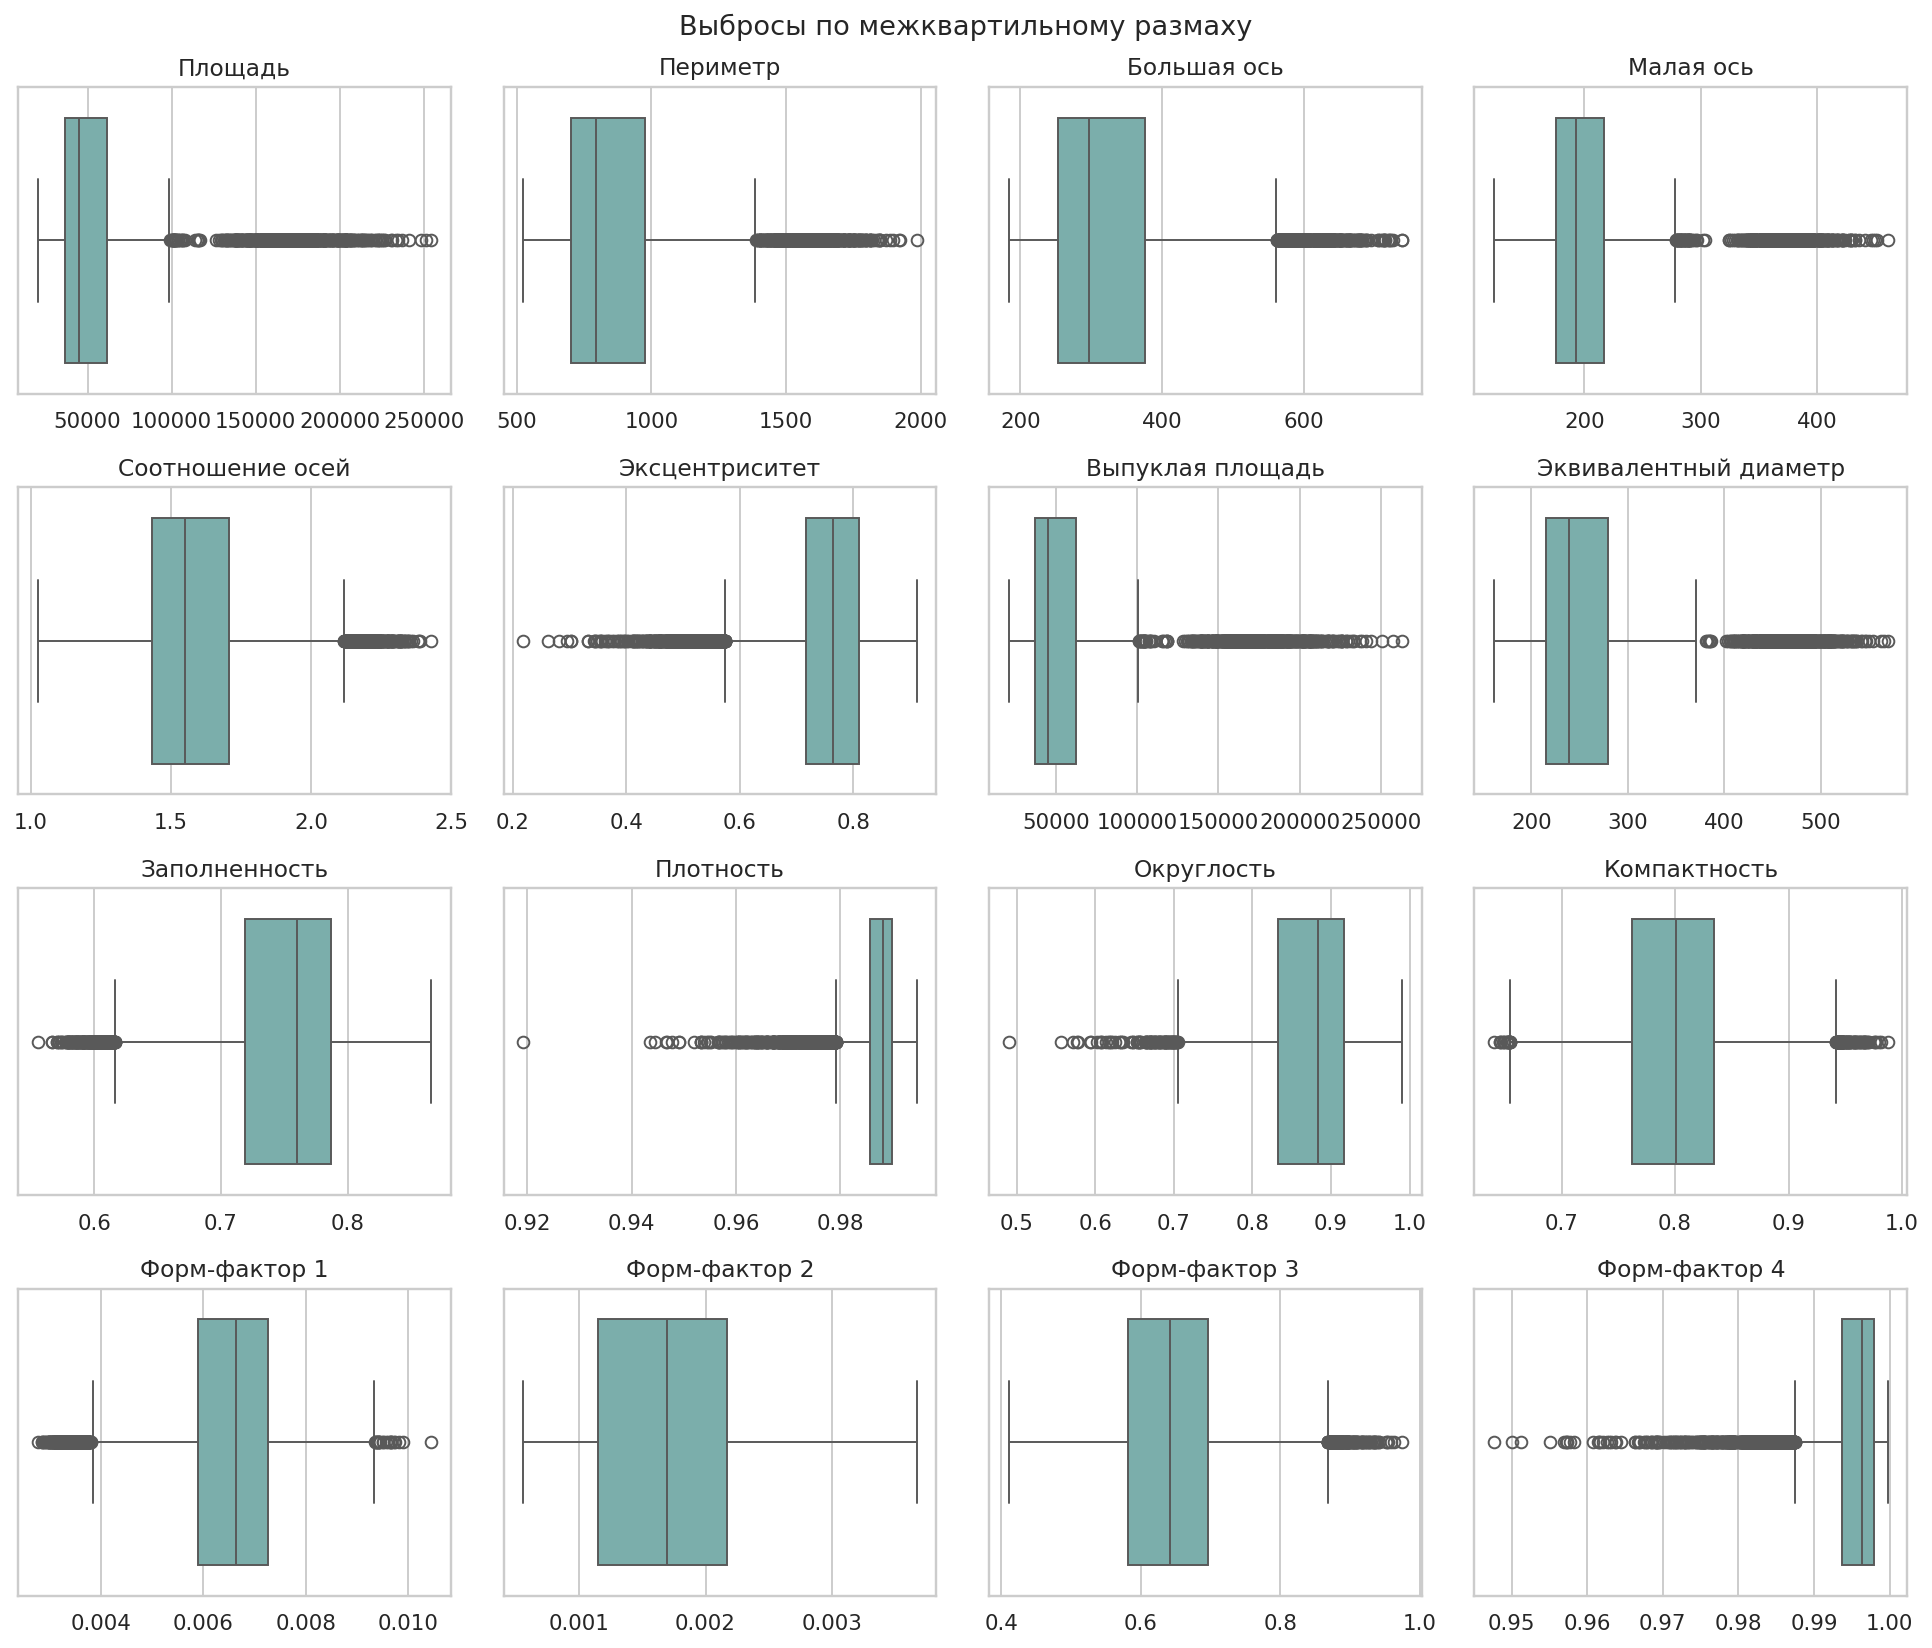

In [ ]:
outlier_rows = []
outlier_mask = pd.Series(False, index=raw.index)
for column in FEATURES:
    q1 = raw[column].quantile(0.25)
    q3 = raw[column].quantile(0.75)
    iqr = q3 - q1
    mask = (raw[column] < q1 - 1.5 * iqr) | (raw[column] > q3 + 1.5 * iqr)
    outlier_mask = outlier_mask | mask
    outlier_rows.append({"Признак": LABELS[column], "выбросы по IQR": int(mask.sum())})
outlier_table = pd.DataFrame(outlier_rows).set_index("Признак")
display(outlier_table)
print(f"Строк хотя бы с одним выбросом: {int(outlier_mask.sum())}")
bombay_share = float((raw.loc[outlier_mask, TARGET] == "BOMBAY").mean()) if outlier_mask.any() else 0.0
print(f"Доля сорта Бомбей среди таких строк: {bombay_share:.3f}")

fig, axes = plt.subplots(4, 4, figsize=(14, 12))
for ax, column in zip(axes.ravel(), FEATURES):
    sns.boxplot(x=raw[column], ax=ax, color="#72B7B2")
    ax.set_title(LABELS[column])
    ax.set_xlabel("")
fig.suptitle("Выбросы по межквартильному размаху", fontsize=14)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "03_boxplots.png", bbox_inches="tight")
plt.show()


Удалены как дубли при |r| > 0,95:
- Периметр
- Большая ось
- Малая ось
- Выпуклая площадь
- Эквивалентный диаметр
- Компактность
- Форм-фактор 3
Осталось признаков: 9


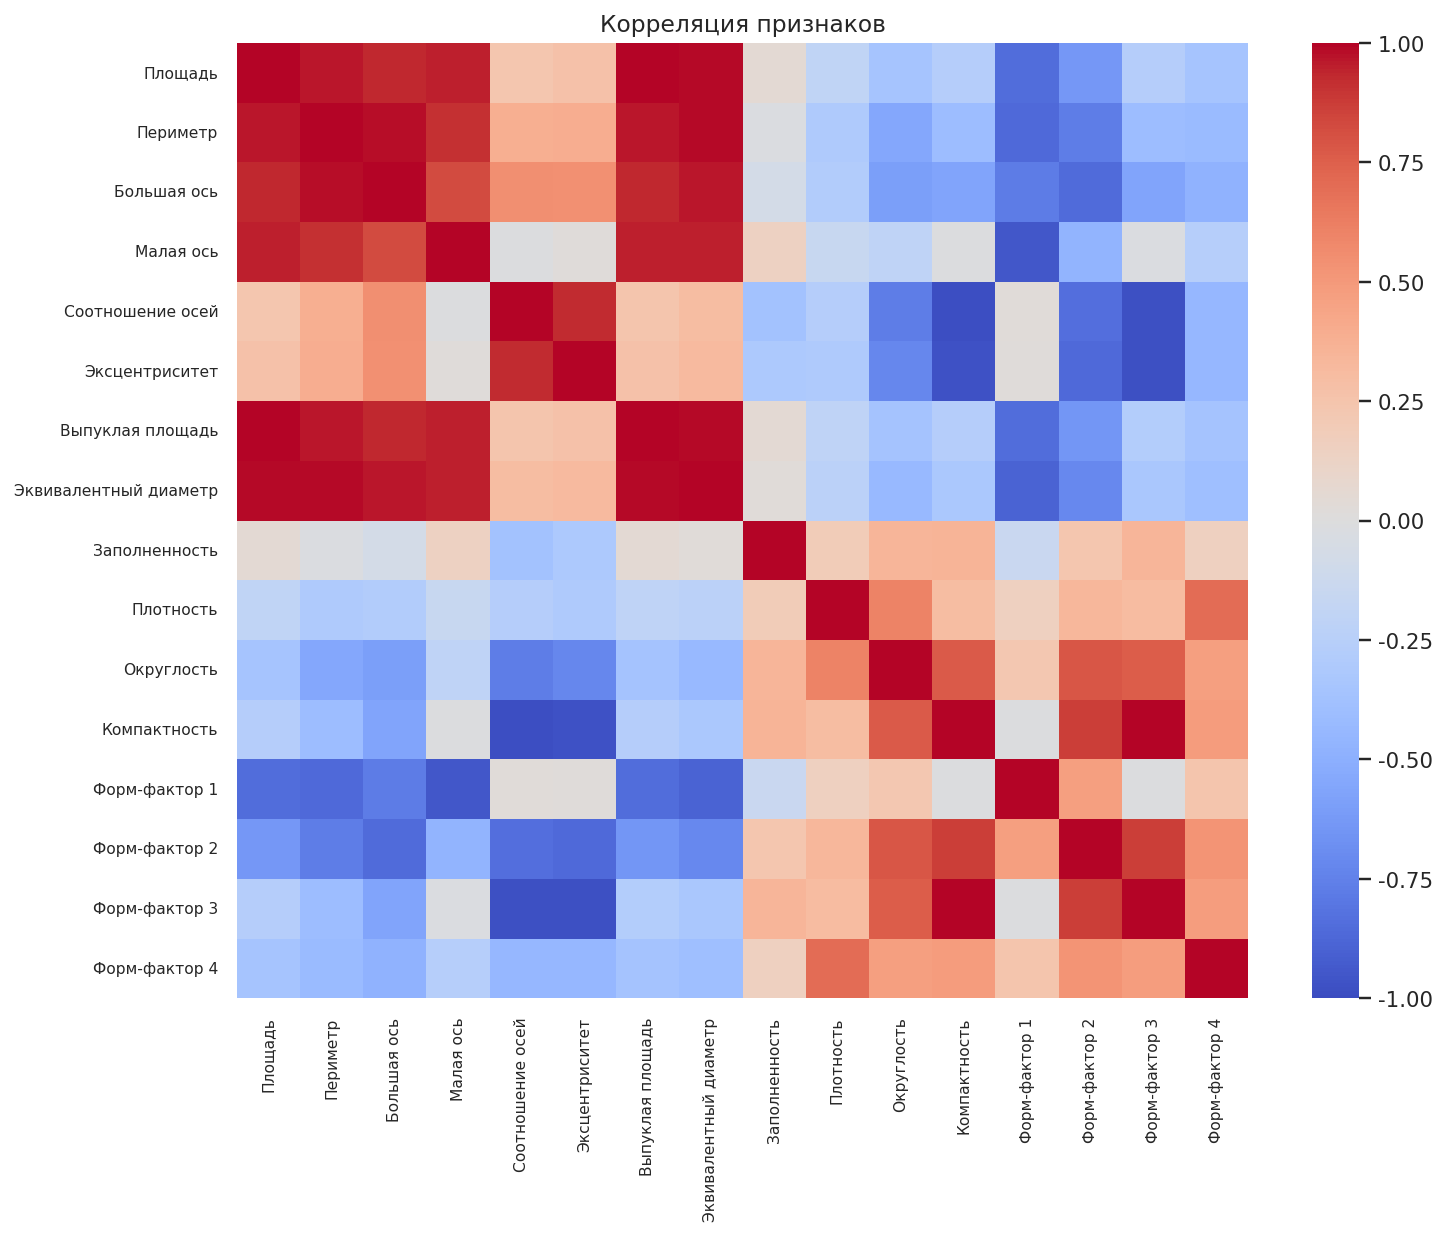

In [ ]:
corr = raw[FEATURES].corr()
corr.rename(index=LABELS, columns=LABELS).to_csv(OUTPUT_DIR / "correlation.csv", encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    corr.rename(index=LABELS, columns=LABELS),
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    ax=ax,
    xticklabels=True,
    yticklabels=True,
)
ax.tick_params(axis="both", labelsize=8)
ax.set_title("Корреляция признаков")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "04_correlation.png", bbox_inches="tight")
plt.show()

abs_corr = corr.abs()
upper = abs_corr.where(np.triu(np.ones(abs_corr.shape), k=1).astype(bool))
dropped = [column for column in upper.columns if (upper[column] > CORR_THRESHOLD).any()]
kept = [column for column in FEATURES if column not in dropped]
print("Удалены как дубли при |r| > 0,95:")
for column in dropped:
    print(f"- {LABELS[column]}")
print(f"Осталось признаков: {len(kept)}")


### Пояснение к значимости признаков

- Площадь, периметр, длины осей, выпуклая площадь и эквивалентный диаметр описывают один и тот же размер зерна и коррелируют выше 0,95. Компактность дублирует третий форм-фактор.
- При пороге |r| > 0,95 из модели убраны: Периметр, Большая ось, Малая ось, Выпуклая площадь, Эквивалентный диаметр, Компактность, Форм-фактор 3.
- В кластеризации остаются 9 признаков: Площадь, Соотношение осей, Эксцентриситет, Заполненность, Плотность, Округлость, Форм-фактор 1, Форм-фактор 2, Форм-фактор 4. Так размер учитывается один раз, а форма — отдельно, и K-means не растягивает расстояние повторными копиями площади.


,mean,std
Площадь,0.0,1.0
Соотношение осей,-0.0,1.0
Эксцентриситет,-0.0,1.0
Заполненность,0.0,1.0
Плотность,0.0,1.0
Округлость,0.0,1.0
Форм-фактор 1,0.0,1.0
Форм-фактор 2,-0.0,1.0
Форм-фактор 4,0.0,1.0


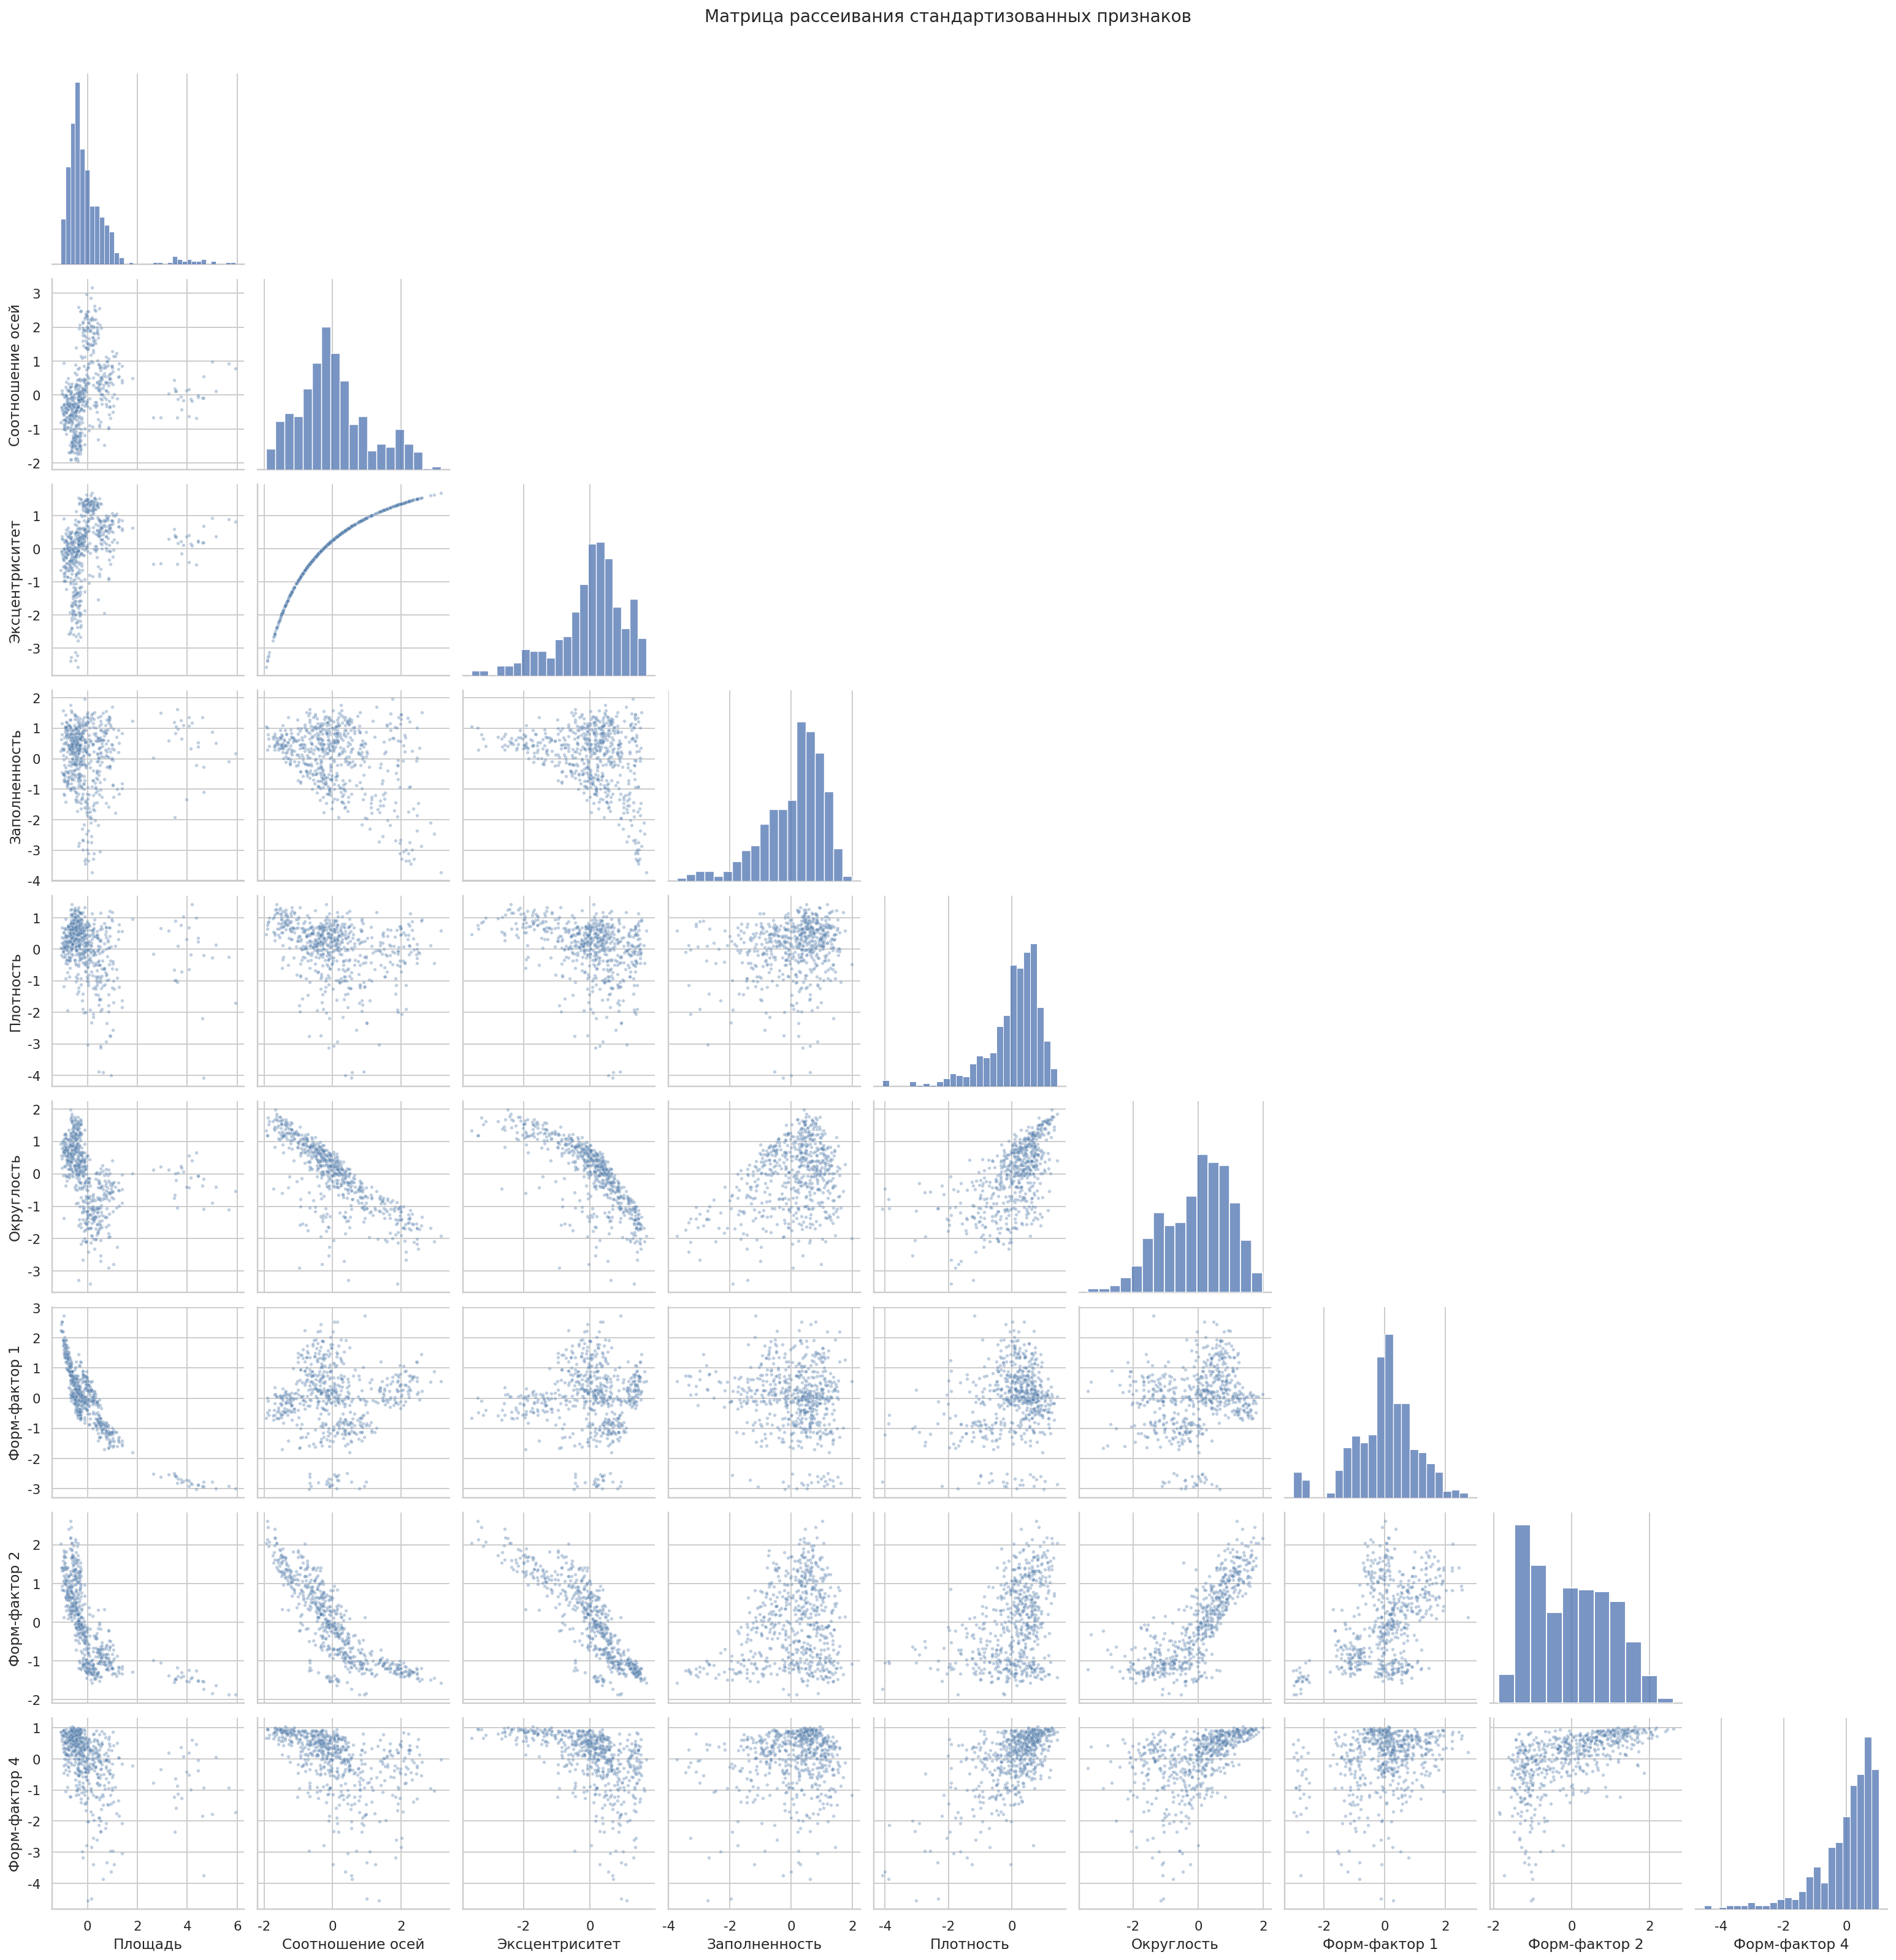

In [ ]:
x = raw[kept].copy()
y = raw[TARGET].copy()
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)
scaled_frame = pd.DataFrame(x_scaled, columns=kept)
display(scaled_frame.describe().T[["mean", "std"]].rename(index=LABELS).round(3))

plot_frame = scaled_frame.copy()
plot_frame.columns = [LABELS[column] for column in kept]
sample = plot_frame.sample(n=600, random_state=RANDOM_STATE)
grid = sns.pairplot(sample, corner=True, plot_kws={"s": 8, "alpha": 0.35, "color": "#4C78A8"}, diag_kind="hist")
grid.figure.suptitle("Матрица рассеивания стандартизованных признаков", y=1.02)
grid.figure.savefig(OUTPUT_DIR / "05_pairplot.png", bbox_inches="tight")
plt.show()


### Пояснение к масштабированию и матрице рассеивания

- Признаки живут в разных единицах: площадь измеряется десятками тысяч пикселей, эксцентриситет и округлость лежат около единицы. Евклидово расстояние K-means и GMM без масштаба почти целиком определяется площадью.
- Выбран **StandardScaler**: после него каждый оставшийся признак имеет среднее 0 и стандартное отклонение 1. MinMax сжал бы все значения в отрезок [0, 1] и оставил бы влияние одного самого большого зерна на края диапазона. RobustScaler понадобился бы, если бы крайние точки были ошибками; здесь крупный сорт — настоящая группа.
- На матрице рассеивания видна вытянутая структура по размеру и соотношению осей. Облака пересекаются, плотности и формы групп разные: часть зёрен компактна, часть вытянута. Поэтому рядом с K-means, который ищет шаровые группы равного влияния, берём EM-алгоритм Gaussian Mixture: он допускает эллиптические компоненты и разную ковариацию.


Локоть: k=6
Максимум силуэта: k=2
Выбрано k=6


,k,инерция,силуэт
0,2,77920.889,0.345
1,3,66514.028,0.336
2,4,55143.335,0.290
3,5,47501.959,0.303
4,6,40507.780,0.308
5,7,37040.634,0.307
6,8,33939.066,0.267
7,9,31457.136,0.269
8,10,29256.213,0.273


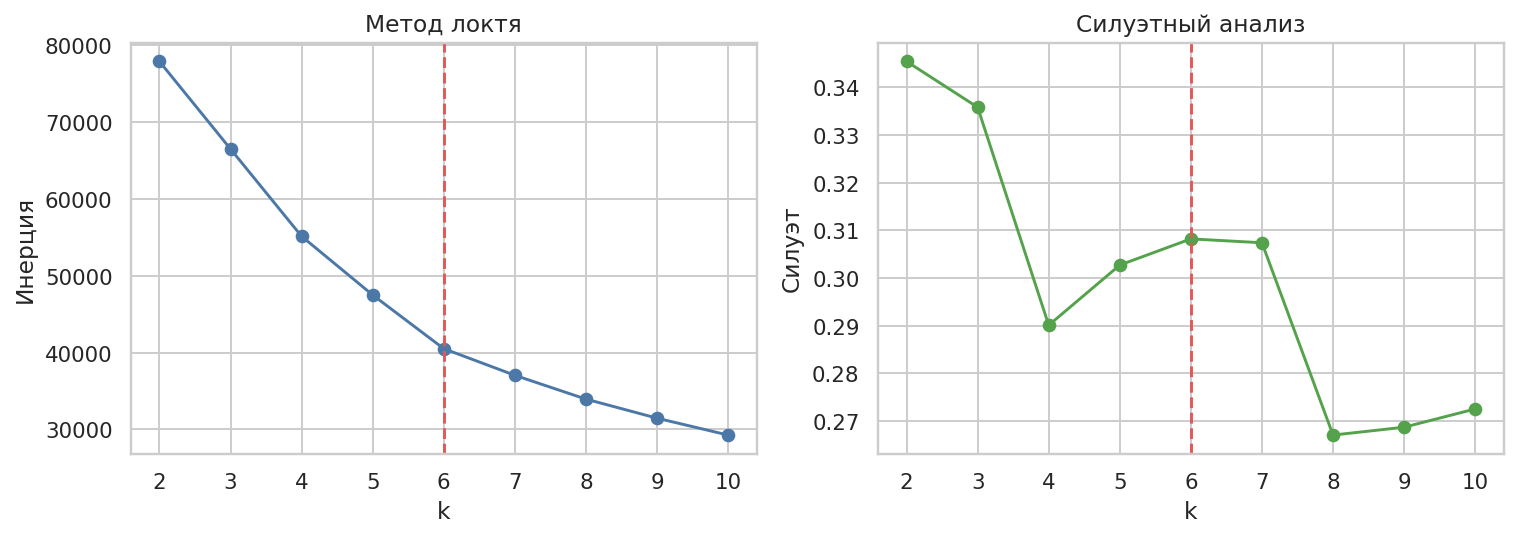

In [ ]:
ks = list(range(2, 11))
inertias = []
silhouettes = []
for k in ks:
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = model.fit_predict(x_scaled)
    inertias.append(float(model.inertia_))
    silhouettes.append(float(silhouette_score(x_scaled, labels, sample_size=3000, random_state=RANDOM_STATE)))

drops = [(inertias[i] - inertias[i + 1]) / inertias[i] for i in range(len(inertias) - 1)]
elbow_k = ks[-1]
for k, drop in zip(ks[:-1], drops):
    if drop < 0.10:
        elbow_k = k
        break
silhouette_k = ks[int(np.argmax(silhouettes))]
if silhouettes[ks.index(silhouette_k)] - silhouettes[ks.index(elbow_k)] < 0.05:
    best_k = elbow_k
else:
    best_k = silhouette_k

k_table = pd.DataFrame({"k": ks, "инерция": inertias, "силуэт": silhouettes})
k_table.to_csv(OUTPUT_DIR / "k_selection.csv", index=False, encoding="utf-8-sig")
display(k_table.round(3))
print(f"Локоть: k={elbow_k}")
print(f"Максимум силуэта: k={silhouette_k}")
print(f"Выбрано k={best_k}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ks, inertias, marker="o", color="#4C78A8")
axes[0].axvline(best_k, color="#E45756", linestyle="--")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Инерция")
axes[0].set_title("Метод локтя")
axes[1].plot(ks, silhouettes, marker="o", color="#54A24B")
axes[1].axvline(best_k, color="#E45756", linestyle="--")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Силуэт")
axes[1].set_title("Силуэтный анализ")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "06_k_selection.png", bbox_inches="tight")
plt.show()


### Пояснение к выбору числа кластеров

- Для k от 2 до 10 посчитаны инерция K-means и силуэт. Силуэт оценивается по одной и той же случайной подвыборке из 3000 точек, чтобы сравнение k было устойчивым по времени.
- Максимум силуэта приходится на **k = 2** (значение 0,345). Кривая при этом пологая: у локтя силуэт равен 0,308.
- Локоть определён как первое k, после которого относительное падение инерции становится меньше 0,10. Это **k = 6**.
- В работу берётся **k = 6**: разница силуэтов меньше 0,05, а инерция как раз перестаёт быстро падать. Известные 7 сортов на этот выбор не влияют.


In [ ]:
def jaccard_index(y_true, y_pred):
    matrix = pair_confusion_matrix(y_true, y_pred)
    true_negative, false_positive, false_negative, true_positive = matrix.ravel()
    denominator = true_positive + false_positive + false_negative
    if denominator == 0:
        return 0.0
    return float(true_positive / denominator)


def clustering_metrics(name, labels, centers):
    points = np.asarray(x_scaled)
    intra = []
    for index, center in enumerate(centers):
        members = points[labels == index]
        if len(members) == 0:
            continue
        intra.append(float(np.mean(np.linalg.norm(members - center, axis=1))))
    distances = np.linalg.norm(centers[:, None, :] - centers[None, :, :], axis=2)
    upper = distances[np.triu_indices(len(centers), k=1)]
    return {
        "Модель": name,
        "Силуэт": float(silhouette_score(points, labels, sample_size=3000, random_state=RANDOM_STATE)),
        "Calinski-Harabasz": float(calinski_harabasz_score(points, labels)),
        "Davies-Bouldin": float(davies_bouldin_score(points, labels)),
        "Среднее внутри кластера": float(np.mean(intra)),
        "Среднее между центрами": float(np.mean(upper)),
        "Минимум между центрами": float(np.min(upper)),
        "Rand": float(rand_score(y, labels)),
        "ARI": float(adjusted_rand_score(y, labels)),
        "NMI": float(normalized_mutual_info_score(y, labels)),
        "Жаккар": jaccard_index(y, labels),
    }


kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE)
kmeans_labels = kmeans.fit_predict(x_scaled)
kmeans_centers = kmeans.cluster_centers_

covariance_rows = []
gmm_models = {}
for covariance in ("spherical", "diag", "tied", "full"):
    model = GaussianMixture(
        n_components=best_k,
        covariance_type=covariance,
        n_init=2,
        reg_covar=1e-4,
        random_state=RANDOM_STATE,
    )
    labels = model.fit_predict(x_scaled)
    score = float(silhouette_score(x_scaled, labels, sample_size=3000, random_state=RANDOM_STATE))
    covariance_rows.append({"ковариация": covariance, "силуэт": score, "BIC": float(model.bic(x_scaled))})
    gmm_models[covariance] = (model, labels)

covariance_table = pd.DataFrame(covariance_rows).set_index("ковариация")
best_covariance = covariance_table["силуэт"].idxmax()
gmm, gmm_labels = gmm_models[best_covariance]
gmm_centers = gmm.means_

metric_rows = [
    clustering_metrics("K-means", kmeans_labels, kmeans_centers),
    clustering_metrics("GMM", gmm_labels, gmm_centers),
]
metrics = pd.DataFrame(metric_rows).set_index("Модель")
metrics.to_csv(OUTPUT_DIR / "metrics_classical.csv", encoding="utf-8-sig")
covariance_table.to_csv(OUTPUT_DIR / "gmm_covariance.csv", encoding="utf-8-sig")
display(metrics.round(3))
display(covariance_table.round(3))


def centers_in_original(centers):
    frame = pd.DataFrame(scaler.inverse_transform(centers), columns=kept)
    frame.columns = [LABELS[column] for column in kept]
    return frame


kmeans_original = centers_in_original(kmeans_centers)
kmeans_original.index = [f"кластер {i}" for i in range(best_k)]
kmeans_original.to_csv(OUTPUT_DIR / "kmeans_centers.csv", encoding="utf-8-sig")
display(kmeans_original.round(2))

crosstab = pd.crosstab(
    pd.Series(kmeans_labels, name="кластер K-means"),
    y.map(VARIETY),
)
crosstab.to_csv(OUTPUT_DIR / "kmeans_crosstab.csv", encoding="utf-8-sig")
display(crosstab)


,Силуэт,Calinski-Harabasz,Davies-Bouldin,Среднее внутри кластера,Среднее между центрами,Минимум между центрами,Rand,ARI,NMI,Жаккар
Модель,,,,,,,,,,
K-means,0.308,5507.537,1.138,1.768,4.809,2.693,0.833,0.513,0.62,0.443
GMM,0.298,4904.599,1.122,1.762,4.929,2.802,0.813,0.504,0.67,0.444


,силуэт,BIC
ковариация,,
spherical,0.291,237878.436
diag,0.270,197899.223
tied,0.298,132869.502
full,0.272,-3584.459


,Площадь,Соотношение осей,Эксцентриситет,Заполненность,Плотность,Округлость,Форм-фактор 1,Форм-фактор 2,Форм-фактор 4
кластер 0,173448.27,1.58,0.77,0.78,0.99,0.87,0.00,0.0,0.99
кластер 1,37134.00,1.52,0.75,0.75,0.99,0.90,0.01,0.0,1.00
кластер 2,38620.09,1.24,0.58,0.77,0.99,0.95,0.01,0.0,1.00
кластер 3,69941.21,1.65,0.79,0.76,0.99,0.83,0.01,0.0,0.99
кластер 4,53644.26,2.02,0.87,0.69,0.99,0.80,0.01,0.0,0.99
кластер 5,65469.43,1.77,0.82,0.73,0.97,0.80,0.01,0.0,0.98


Class,Барбунья,Бомбей,Дермасон,Кали,Секер,Сира,Хороз
кластер K-means,,,,,,,
0,0,513,0,0,0,0,0
1,21,0,3241,6,153,2145,25
2,14,0,253,2,1859,22,0
3,1202,0,5,1271,9,286,137
4,24,0,18,56,1,148,1556
5,61,9,29,295,5,35,210


### Пояснение к K-means и GMM

- **K-means** делит зерна на 6 групп вокруг центров и минимизирует сумму квадратов расстояний. Он уместен, когда после стандартизации группы компактны.
- **GMM** — это EM-алгоритм для смеси нормальных распределений. Компонента задаётся центром и ковариацией, поэтому эллиптические группы описываются лучше, чем равные шары.
- При сравнении ковариаций лучший силуэт у типа **tied**. Его и берём как основной GMM.
- Внутренние метрики считаются в стандартизованном пространстве. Выше лучше у силуэта и Calinski–Harabasz, ниже лучше у Davies–Bouldin. Внешние Rand, ARI, NMI и Жаккар сравнивают разбиение с сортами; сами сорта в обучение не входили.
- K-means: силуэт 0,308, ARI 0,513, среднее расстояние до центра 1,768, среднее расстояние между центрами 4,809.
- GMM: силуэт 0,298, ARI 0,504, среднее расстояние до центра 1,762, среднее расстояние между центрами 4,929.


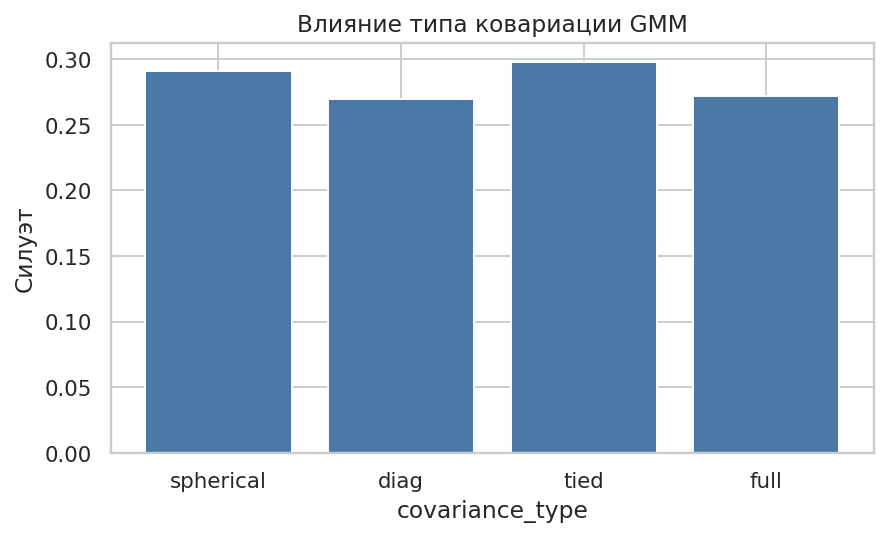

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(covariance_table.index, covariance_table["силуэт"], color="#4C78A8")
ax.set_ylabel("Силуэт")
ax.set_xlabel("covariance_type")
ax.set_title("Влияние типа ковариации GMM")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "07_gmm_covariance.png", bbox_inches="tight")
plt.show()


### Пояснение к влиянию параметров

- Число кластеров меняет и инерцию, и силуэт: это уже видно на графике подбора k. После выбранного k новые центры уменьшают инерцию медленнее.
- У GMM при фиксированном k = 6 сравнены `spherical`, `diag`, `tied` и `full`. Силуэт лучшего типа (tied) равен 0,298, худшего — 0,270.
- `spherical` заставляет все компоненты быть шарами, `diag` разрешает разный масштаб по осям без наклона, `tied` даёт одну общую форму всем группам, `full` оценивает отдельный эллипс на каждую. Разница силуэтов показывает, нужна ли эта свобода на данных о зёрнах.


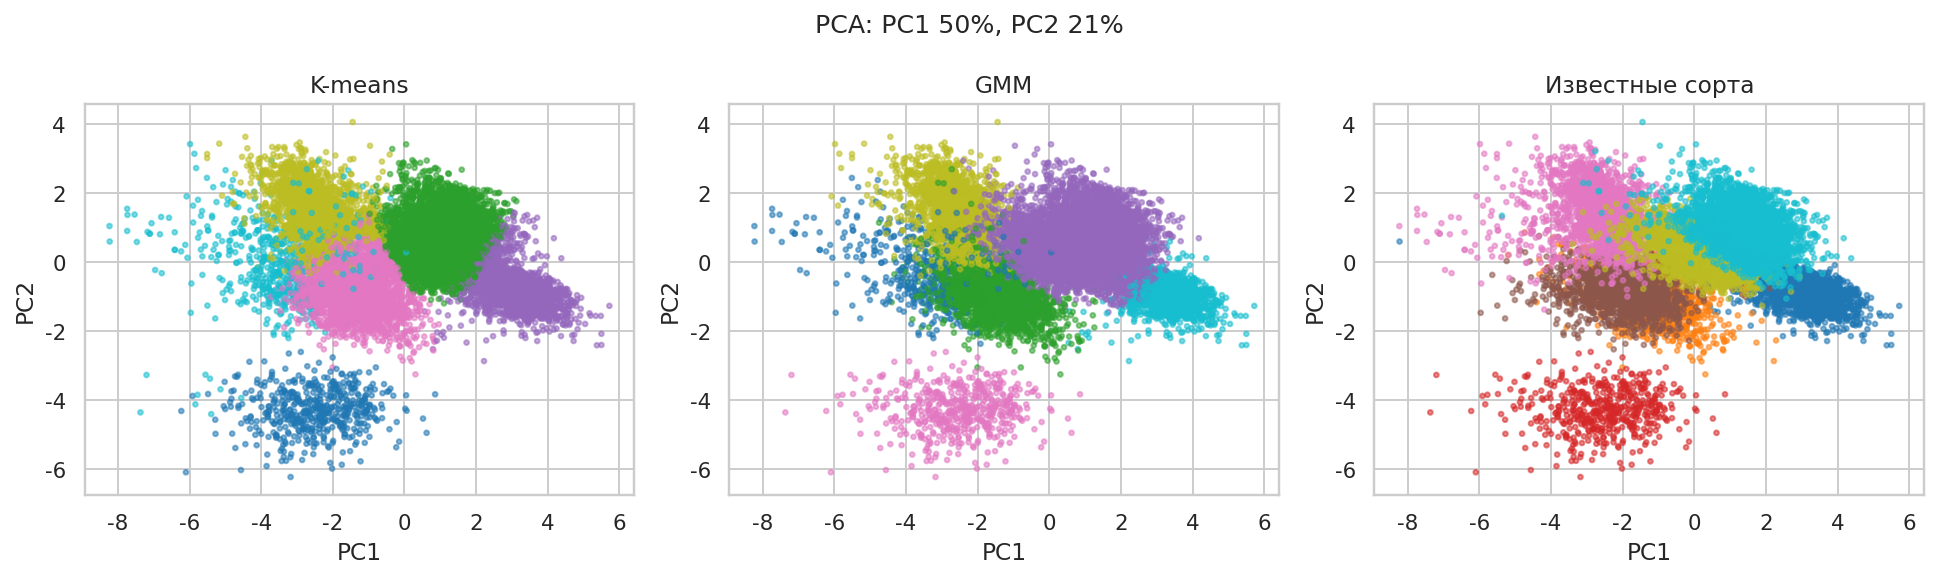

In [ ]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
xy = pca.fit_transform(x_scaled)
explained = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
panels = (
    (kmeans_labels, "K-means"),
    (gmm_labels, "GMM"),
    (pd.factorize(y)[0], "Известные сорта"),
)
for ax, (labels, title) in zip(axes, panels):
    ax.scatter(xy[:, 0], xy[:, 1], c=labels, cmap="tab10", s=6, alpha=0.55)
    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
fig.suptitle(f"PCA: PC1 {explained[0]:.0%}, PC2 {explained[1]:.0%}", fontsize=13)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "08_pca_clusters.png", bbox_inches="tight")
plt.show()


### Пояснение к визуализации и центрам K-means

- Две первые главные компоненты сохраняют 50,2% и 20,7% дисперсии. На плоскости видны и разбиения алгоритмов, и известные сорта. Совпадение цветов между рисунками не требуется: номера кластеров и номера сортов задаются независимо.
- Центры K-means переведены обратно из стандартизованного масштаба. По ним группы читаются так:

- Кластер 0: чаще всего Бомбей (1,00 доли объектов), площадь центра 173448 пикселей, соотношение осей 1,58.
- Кластер 1: чаще всего Дермасон (0,58 доли объектов), площадь центра 37134 пикселей, соотношение осей 1,52.
- Кластер 2: чаще всего Секер (0,86 доли объектов), площадь центра 38620 пикселей, соотношение осей 1,24.
- Кластер 3: чаще всего Кали (0,44 доли объектов), площадь центра 69941 пикселей, соотношение осей 1,65.
- Кластер 4: чаще всего Хороз (0,86 доли объектов), площадь центра 53644 пикселей, соотношение осей 2,02.
- Кластер 5: чаще всего Кали (0,46 доли объектов), площадь центра 65469 пикселей, соотношение осей 1,77.


latent=2, lr=0.001, l2=0.0: MSE=0.1133, silhouette=0.450
latent=2, lr=0.001, l2=0.0001: MSE=0.1070, silhouette=0.452
latent=2, lr=0.01, l2=0.0: MSE=0.0909, silhouette=0.456
latent=2, lr=0.01, l2=0.0001: MSE=0.1165, silhouette=0.452
latent=4, lr=0.001, l2=0.0: MSE=0.0615, silhouette=0.407
latent=4, lr=0.001, l2=0.0001: MSE=0.0760, silhouette=0.417
latent=4, lr=0.01, l2=0.0: MSE=0.0178, silhouette=0.275
latent=4, lr=0.01, l2=0.0001: MSE=0.0239, silhouette=0.302
latent=8, lr=0.001, l2=0.0: MSE=0.0650, silhouette=0.423
latent=8, lr=0.001, l2=0.0001: MSE=0.0392, silhouette=0.329
latent=8, lr=0.01, l2=0.0: MSE=0.0070, silhouette=0.268
latent=8, lr=0.01, l2=0.0001: MSE=0.0114, silhouette=0.318


,латентность,скорость,L2,MSE,силуэт в латентном пространстве
0,2,0.001,0.0000,0.1133,0.4503
1,2,0.001,0.0001,0.1070,0.4518
2,2,0.010,0.0000,0.0909,0.4556
3,2,0.010,0.0001,0.1165,0.4517
4,4,0.001,0.0000,0.0615,0.4068
5,4,0.001,0.0001,0.0760,0.4167
6,4,0.010,0.0000,0.0178,0.2750
7,4,0.010,0.0001,0.0239,0.3020
8,8,0.001,0.0000,0.0650,0.4235
9,8,0.001,0.0001,0.0392,0.3287


,k,силуэт в латентном пространстве
0,5,0.453
1,6,0.456
2,7,0.408


,Силуэт,Calinski-Harabasz,Davies-Bouldin,Среднее внутри кластера,Среднее между центрами,Минимум между центрами,Rand,ARI,NMI,Жаккар
Модель,,,,,,,,,,
Автокодировщик + K-means,0.288,5197.378,1.103,1.752,4.922,2.663,0.816,0.468,0.586,0.408
DEC,0.191,3285.927,1.168,1.863,5.139,2.636,0.722,0.302,0.457,0.301


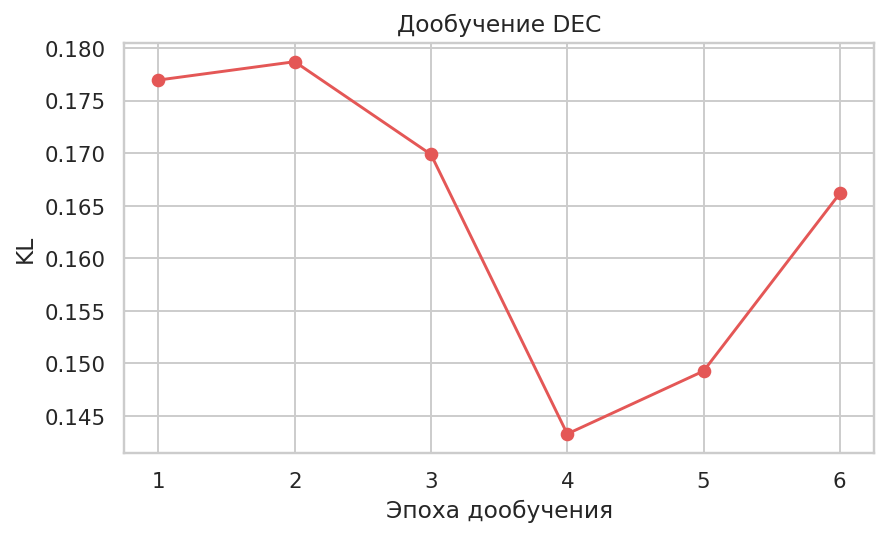

In [ ]:
def build_autoencoder(latent_dim, l2):
    regularizer = tf.keras.regularizers.l2(l2) if l2 else None
    inputs = tf.keras.Input(shape=(x_scaled.shape[1],))
    hidden = tf.keras.layers.Dense(32, activation="relu", kernel_regularizer=regularizer)(inputs)
    hidden = tf.keras.layers.Dense(16, activation="relu", kernel_regularizer=regularizer)(hidden)
    latent = tf.keras.layers.Dense(latent_dim, activation="linear", name="latent")(hidden)
    hidden = tf.keras.layers.Dense(16, activation="relu", kernel_regularizer=regularizer)(latent)
    hidden = tf.keras.layers.Dense(32, activation="relu", kernel_regularizer=regularizer)(hidden)
    outputs = tf.keras.layers.Dense(x_scaled.shape[1], activation="linear")(hidden)
    autoencoder = tf.keras.Model(inputs, outputs)
    encoder = tf.keras.Model(inputs, latent)
    return autoencoder, encoder


def soft_assign(latent, centers, alpha=1.0):
    distance = tf.reduce_sum(tf.square(tf.expand_dims(latent, 1) - tf.expand_dims(centers, 0)), axis=2)
    weights = tf.pow(1.0 + distance / alpha, -(alpha + 1.0) / 2.0)
    return weights / tf.reduce_sum(weights, axis=1, keepdims=True)


def target_distribution(weights):
    frequency = tf.square(weights) / tf.reduce_sum(weights, axis=0, keepdims=True)
    return frequency / tf.reduce_sum(frequency, axis=1, keepdims=True)


def latent_silhouette(latent, n_clusters):
    labels = KMeans(n_clusters=n_clusters, n_init=10, random_state=RANDOM_STATE).fit_predict(latent)
    score = float(silhouette_score(latent, labels, sample_size=3000, random_state=RANDOM_STATE))
    return labels, score


grid_rows = []
trained = []
for latent_dim in (2, 4, 8):
    for learning_rate in (0.001, 0.01):
        for l2 in (0.0, 1e-4):
            autoencoder, encoder = build_autoencoder(latent_dim, l2)
            autoencoder.compile(optimizer=tf.keras.optimizers.Adam(learning_rate), loss="mse")
            history = autoencoder.fit(
                x_scaled, x_scaled, epochs=8, batch_size=512, validation_split=0.1, verbose=0
            )
            latent = encoder.predict(x_scaled, verbose=0)
            _, score = latent_silhouette(latent, best_k)
            row = {
                "латентность": latent_dim,
                "скорость": learning_rate,
                "L2": l2,
                "MSE": float(history.history["val_loss"][-1]),
                "силуэт в латентном пространстве": score,
            }
            grid_rows.append(row)
            trained.append((row, encoder, latent))
            print(
                f"latent={latent_dim}, lr={learning_rate}, l2={l2}: "
                f"MSE={row['MSE']:.4f}, silhouette={score:.3f}"
            )

grid_table = pd.DataFrame(grid_rows)
grid_table.to_csv(OUTPUT_DIR / "dec_grid.csv", index=False, encoding="utf-8-sig")
display(grid_table.round(4))
best_row = grid_table.sort_values(
    ["силуэт в латентном пространстве", "MSE"], ascending=[False, True]
).iloc[0]
best_pack = trained[int(grid_table.index.get_loc(best_row.name))]
best_encoder = best_pack[1]
best_latent = best_pack[2]

k_candidates = sorted({max(2, best_k - 1), best_k, best_k + 1})
k_rows = []
for n_clusters in k_candidates:
    labels, score = latent_silhouette(best_latent, n_clusters)
    k_rows.append({"k": n_clusters, "силуэт в латентном пространстве": score, "метки": labels})
latent_k_table = pd.DataFrame([{key: value for key, value in row.items() if key != "метки"} for row in k_rows])
display(latent_k_table.round(3))
chosen_k_row = max(k_rows, key=lambda item: item["силуэт в латентном пространстве"])
deep_k = int(chosen_k_row["k"])
ae_labels = chosen_k_row["метки"]
ae_model = KMeans(n_clusters=deep_k, n_init=10, random_state=RANDOM_STATE).fit(best_latent)

centers = tf.Variable(ae_model.cluster_centers_.astype(np.float32))
optimizer = tf.keras.optimizers.Adam(float(best_row["скорость"]))
x_tensor = tf.constant(x_scaled.astype(np.float32))
dec_losses = []
for epoch in range(6):
    latent_now = best_encoder(x_tensor, training=False)
    target = tf.stop_gradient(target_distribution(soft_assign(latent_now, centers)))
    batches = tf.data.Dataset.from_tensor_slices((x_tensor, target)).batch(256)
    epoch_losses = []
    for batch_x, batch_target in batches:
        with tf.GradientTape() as tape:
            latent_batch = best_encoder(batch_x, training=True)
            weights = soft_assign(latent_batch, centers)
            loss = tf.reduce_mean(tf.reduce_sum(batch_target * tf.math.log((batch_target + 1e-8) / (weights + 1e-8)), axis=1))
        variables = best_encoder.trainable_variables + [centers]
        optimizer.apply_gradients(zip(tape.gradient(loss, variables), variables))
        epoch_losses.append(float(loss))
    dec_losses.append(float(np.mean(epoch_losses)))

final_weights = soft_assign(best_encoder(x_tensor, training=False), centers)
dec_labels = tf.argmax(final_weights, axis=1).numpy()
dec_centers_latent = centers.numpy()

ae_space_centers = np.vstack([
    x_scaled[ae_labels == index].mean(axis=0) if np.any(ae_labels == index) else np.zeros(x_scaled.shape[1])
    for index in range(deep_k)
])
dec_space_centers = np.vstack([
    x_scaled[dec_labels == index].mean(axis=0) if np.any(dec_labels == index) else np.zeros(x_scaled.shape[1])
    for index in range(deep_k)
])
ae_metrics = clustering_metrics("Автокодировщик + K-means", ae_labels, ae_space_centers)
dec_metrics = clustering_metrics("DEC", dec_labels, dec_space_centers)
deep_metrics = pd.DataFrame([ae_metrics, dec_metrics]).set_index("Модель")
deep_metrics.to_csv(OUTPUT_DIR / "metrics_deep.csv", encoding="utf-8-sig")
display(deep_metrics.round(3))

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(range(1, len(dec_losses) + 1), dec_losses, marker="o", color="#E45756")
ax.set_xlabel("Эпоха дообучения")
ax.set_ylabel("KL")
ax.set_title("Дообучение DEC")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "09_dec_loss.png", bbox_inches="tight")
plt.show()


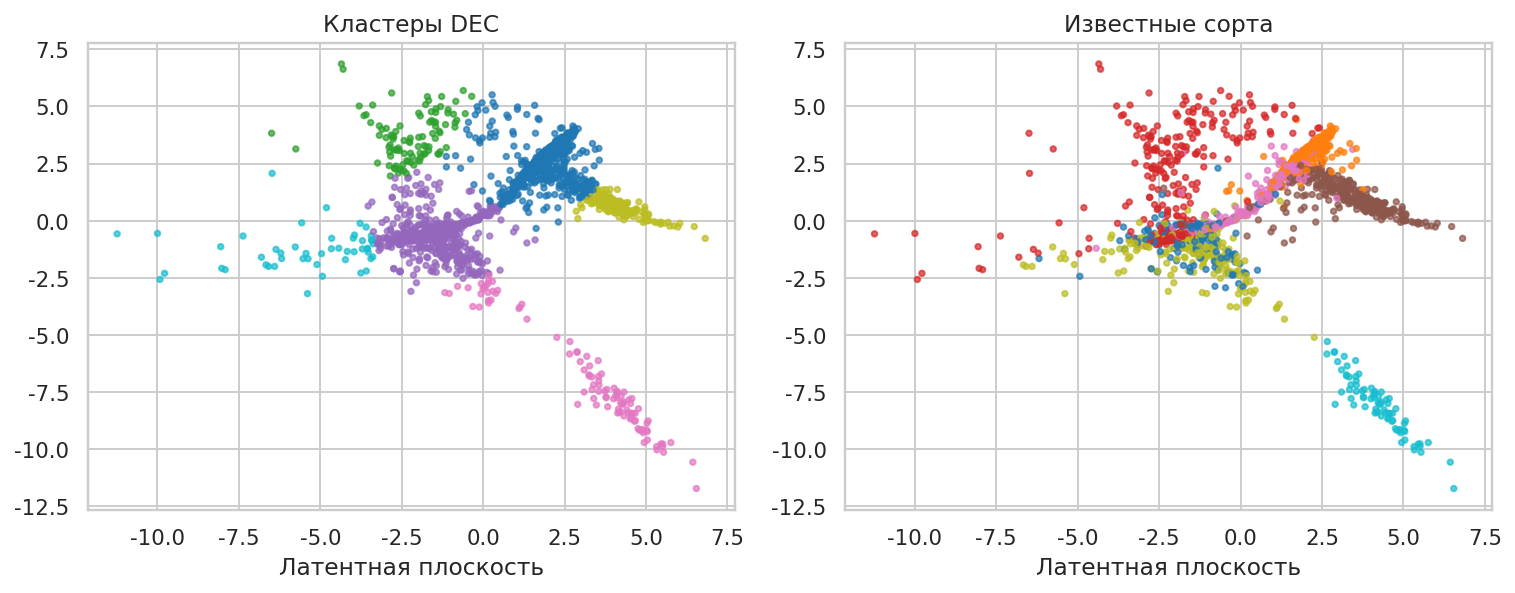

Class,Барбунья,Бомбей,Дермасон,Кали,Секер,Сира,Хороз
кластер DEC,,,,,,,
0,26,0,3443,10,1043,1657,288
1,0,0,8,3,0,1,651
2,1213,0,64,1274,71,968,899
3,48,521,0,137,0,0,0
4,0,0,28,0,909,1,0
5,35,1,3,206,4,9,90


In [ ]:
sample_index = np.random.default_rng(RANDOM_STATE).choice(len(x_scaled), size=2000, replace=False)
latent_sample = best_encoder.predict(x_scaled[sample_index], verbose=0)
if latent_sample.shape[1] == 2:
    embedding = latent_sample
    embedding_name = "Латентная плоскость"
else:
    embedding = TSNE(
        n_components=2,
        perplexity=30,
        learning_rate="auto",
        init="pca",
        max_iter=750,
        random_state=RANDOM_STATE,
    ).fit_transform(latent_sample)
    embedding_name = "t-SNE латентного пространства"

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
axes[0].scatter(embedding[:, 0], embedding[:, 1], c=dec_labels[sample_index], cmap="tab10", s=8, alpha=0.7)
axes[0].set_title("Кластеры DEC")
axes[1].scatter(embedding[:, 0], embedding[:, 1], c=pd.factorize(y.iloc[sample_index])[0], cmap="tab10", s=8, alpha=0.7)
axes[1].set_title("Известные сорта")
for ax in axes:
    ax.set_xlabel(embedding_name)
    ax.set_ylabel("")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "10_latent_space.png", bbox_inches="tight")
plt.show()

dec_crosstab = pd.crosstab(pd.Series(dec_labels, name="кластер DEC"), y.map(VARIETY))
dec_crosstab.to_csv(OUTPUT_DIR / "dec_crosstab.csv", encoding="utf-8-sig")
display(dec_crosstab)


### Пояснение к глубокой кластеризации DEC

- **Зачем.** Классические методы работают в исходных 9 признаках. DEC сначала сжимает их автокодировщиком, а затем уточняет центры в латентном пространстве.
- **Архитектура.** Полносвязная сеть 9 → 32 → 16 → латентный слой → 16 → 32 → 9. Скрытые слои с ReLU, латентный и выходной слои линейные: координаты зерна не нужно обрезать положительной активацией.
- **Функции потерь.** Предобучение минимизирует MSE: выход должен восстановить стандартизованные измерения. Дообучение DEC минимизирует KL между целевым распределением P и мягкими назначениями Стьюдента Q. P строится из Q и на каждом шаге заморожено, как в работе Xie, Girshick и Farhadi (2016). Коэффициент L2 штрафует веса.
- **Подбор.** Сетка: латентность 2, 4 и 8; скорость обучения 0,001 и 0,01; L2 = 0 и 0,0001. Критерий — силуэт K-means в латентном пространстве, без подглядывания в сорта. Лучшая предобученная сеть: латентность 2, скорость 0,01, без штрафа L2. Число кластеров в латентном пространстве выбрано из окрестности классического k и равно **6**.
- Затем 6 эпох DEC двигают и кодировщик, и центры. Метрики DEC и автокодировщика с K-means посчитаны в том же исходном пространстве, что и у классических методов, чтобы таблица была сопоставимой.
- Автокодировщик + K-means: силуэт 0,288, ARI 0,468.
- DEC: силуэт 0,191, ARI 0,302.


,Силуэт,Calinski-Harabasz,Davies-Bouldin,Среднее внутри кластера,Среднее между центрами,Минимум между центрами,Rand,ARI,NMI,Жаккар
Модель,,,,,,,,,,
K-means,0.308,5507.537,1.138,1.768,4.809,2.693,0.833,0.513,0.620,0.443
GMM,0.298,4904.599,1.122,1.762,4.929,2.802,0.813,0.504,0.670,0.444
Автокодировщик + K-means,0.288,5197.378,1.103,1.752,4.922,2.663,0.816,0.468,0.586,0.408
DEC,0.191,3285.927,1.168,1.863,5.139,2.636,0.722,0.302,0.457,0.301


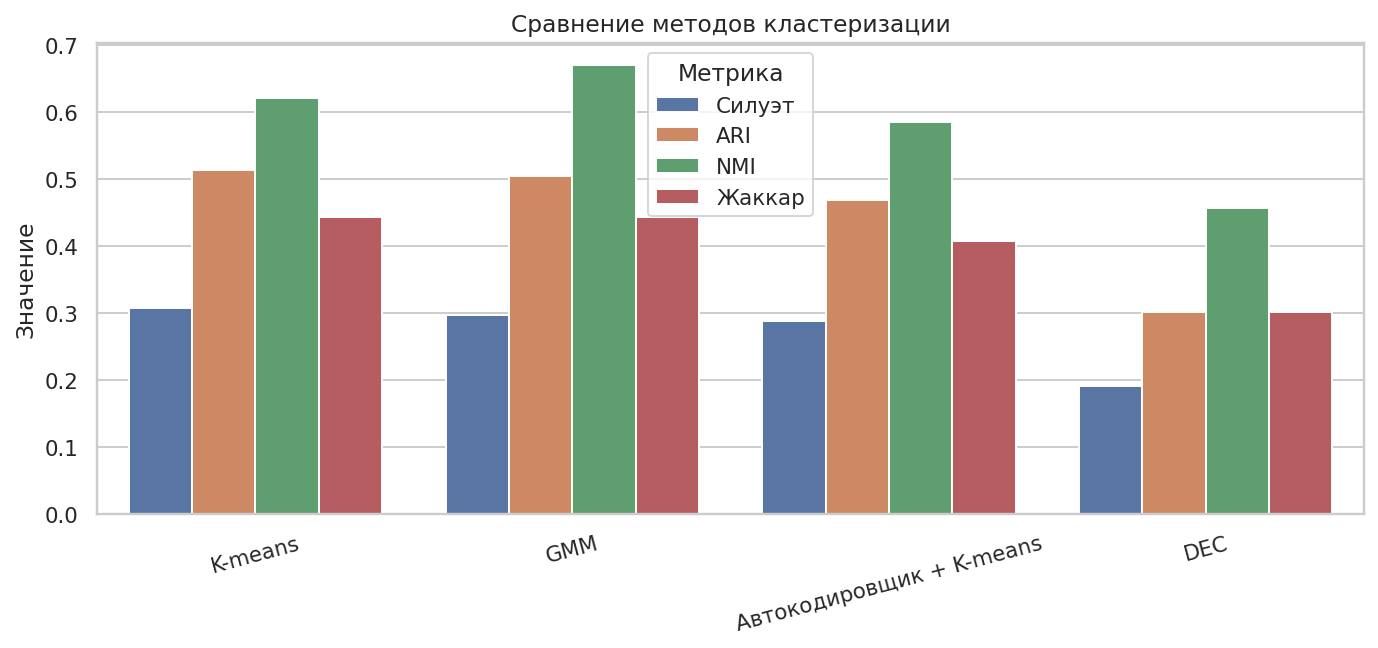

In [ ]:
final_table = pd.concat([metrics, deep_metrics])
final_table.to_csv(OUTPUT_DIR / "metrics_all.csv", encoding="utf-8-sig")
display(final_table.round(3))

plot_frame = final_table.reset_index().melt(
    id_vars="Модель",
    value_vars=["Силуэт", "ARI", "NMI", "Жаккар"],
    var_name="Метрика",
    value_name="Значение",
)
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.barplot(data=plot_frame, x="Модель", y="Значение", hue="Метрика", ax=ax)
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=15)
ax.set_title("Сравнение методов кластеризации")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "11_comparison.png", bbox_inches="tight")
plt.show()


---
## Сравнительный анализ

По силуэту в исходном пространстве лучше **K-means** (0,308). По согласованности с сортами (ARI) лучше **K-means** (0,513).

K-means ищет компактные группы вокруг центров. GMM с ковариацией `tied` разрешает этим группам быть эллипсами. Глубокая модель добавляет нелинейное сжатие. ARI глубокой модели ниже лучшего классического результата на 0,044. Для этой таблицы глубокая кластеризация не нужна: признаки уже числовые и их мало, автокодировщик сжимает почти ту же геометрию, которую видят K-means и GMM.

Близкие сорта, прежде всего Дермасон и Сира, остаются частично смешанными: их форма пересекается, поэтому ни один метод не получает ARI около единицы. Крупный Бомбей и вытянутый Хороз отделяются легче, что видно по центрам и по таблице сорт–кластер.

## Заключение

1. **Данные.** Dry Bean Dataset: 13611 зёрен, 16 признаков, пропусков нет. Сорт отложен и используется только как внешняя метка.
2. **Распределения.** Нормальность не выполняется у 16 признаков. Крайние значения по IQR встречаются у нескольких сортов и оставлены в выборке.
3. **Признаки и масштаб.** После удаления дублей с |r| > 0,95 осталось 9 признаков. StandardScaler выравнивает площадь и безразмерные коэффициенты формы.
4. **Число кластеров.** Локоть даёт k = 6, максимум силуэта — k = 2. В расчётах используется k = 6.
5. **Классические методы.** K-means и GMM (`tied`) дают близкое внутреннее качество. Внешние индексы Rand, ARI, NMI и Жаккар показывают частичное, а не полное совпадение с семью сортами.
6. **Параметры.** Тип ковариации GMM меняет силуэт; выбран `tied`. Число кластеров сильнее всего влияет на инерцию до выбранного k.
7. **DEC.** Лучшая сеть имеет латентность 2, скорость 0,01 и без штрафа L2, число кластеров 6. ARI глубокой модели ниже лучшего классического результата на 0,044. Для этой таблицы глубокая кластеризация не нужна: признаки уже числовые и их мало, автокодировщик сжимает почти ту же геометрию, которую видят K-means и GMM.
8. **Итог.** Для этих геометрических измерений достаточно K-means или GMM. Глубокая кластеризация уместнее там, где признаки сырые и очень большой размерности.

---
## Список использованных источников

1. Dry Bean Dataset // Kaggle. URL: https://www.kaggle.com/datasets/muratkokludataset/dry-bean-dataset
2. Koklu M., Ozkan I. A. Multiclass classification of dry beans using computer vision and machine learning techniques // Computers and Electronics in Agriculture. 2020.
3. Dry Bean // UCI Machine Learning Repository. URL: https://archive.ics.uci.edu/dataset/602/dry+bean+dataset
4. *Hastie T., Tibshirani R., Friedman J.* The Elements of Statistical Learning. 2nd ed. Springer, 2009.
5. Xie J., Girshick R., Farhadi A. Unsupervised Deep Embedding for Clustering Analysis // ICML. 2016.
6. Документация scikit-learn: K-means, Gaussian mixture, метрики кластеризации. URL: https://scikit-learn.org/stable/modules/clustering.html
7. Документация TensorFlow Keras: https://www.tensorflow.org/guide/keras

---
## Приложение

Полный листинг программы приведён в кодовых ячейках этого отчёта. Отдельный файл сценария не используется: ноутбук и есть воспроизводимый код, от загрузки данных до сравнения метрик.
